In [1]:
!pip install tensorflow scikit-learn pandas numpy matplotlib seaborn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.19.0


In [31]:
from keras.datasets import california_housing

(X_train_full, y_train_full), (X_test, y_test) = california_housing.load_data(
    version="small",
    test_split=0.2
)

print("Training features:", X_train_full.shape)
print("Training targets:", y_train_full.shape)
print("Test features:", X_test.shape)
print("Test targets:", y_test.shape)

Training features: (480, 8)
Training targets: (480,)
Test features: (120, 8)
Test targets: (120,)


In [32]:
print("Target minimum:", y_train_full.min())
print("Target maximum:", y_train_full.max())
print("Target mean:", y_train_full.mean())
print("Target median:", np.median(y_train_full))

Target minimum: 60000.0
Target maximum: 500001.0
Target mean: 204178.56
Target median: 182650.0


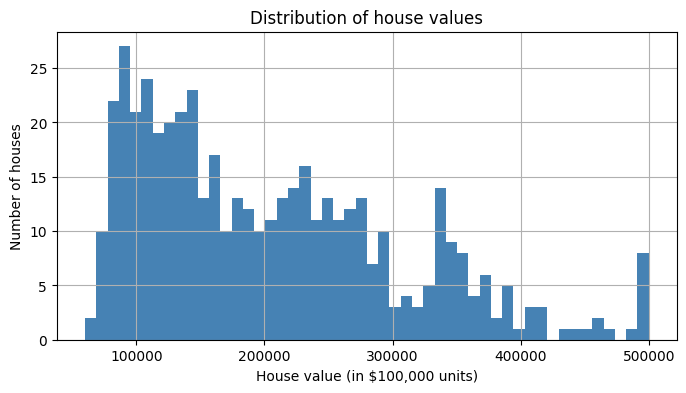

In [5]:
plt.figure(figsize=(8, 4))
plt.hist(y_train_full, bins=50, color="steelblue")
plt.title("Distribution of house values")
plt.xlabel("House value (in $100,000 units)")
plt.ylabel("Number of houses")
plt.grid(True)
plt.show()

In [6]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.20,
    random_state=42
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

Training set: (384, 8)
Validation set: (96, 8)
Test set: (120, 8)


In [7]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Scaled training mean:", X_train_scaled.mean(axis=0).round(3))
print("Scaled training standard deviation:", X_train_scaled.std(axis=0).round(3))

Scaled training mean: [ 0. -0.  0. -0. -0. -0. -0.  0.]
Scaled training standard deviation: [1. 1. 1. 1. 1. 1. 1. 1.]


In [8]:
ann_model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),

    Dense(128, activation="relu"),
    Dropout(0.2),

    Dense(64, activation="relu"),
    Dropout(0.2),

    Dense(1)
])

ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │           1,152 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 9,473 (37.00 KB)

 Trainable params: 9,473 (37.00 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
ann_model.compile(
    loss="mse",
    optimizer="adam",
    metrics=[
        "mae",
        keras.metrics.RootMeanSquaredError(name="rmse")
    ]
)

In [10]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

In [11]:
history_ann = ann_model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 52408123392.0000 - mae: 204797.8594 - rmse: 228928.2031 - val_loss: 50406273024.0000 - val_mae: 201698.7969 - val_rmse: 224513.4062
Epoch 2/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 52407402496.0000 - mae: 204796.2969 - rmse: 228926.6250 - val_loss: 50405519360.0000 - val_mae: 201696.9531 - val_rmse: 224511.7344
Epoch 3/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 52406550528.0000 - mae: 204794.4219 - rmse: 228924.7656 - val_loss: 50404503552.0000 - val_mae: 201694.5469 - val_rmse: 224509.4688
Epoch 4/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 52405301248.0000 - mae: 204791.6094 - rmse: 228922.0469 - val_loss: 50403037184.0000 - val_mae: 201691.0469 - val_rmse: 224506.2031
Epoch 5/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 52403552256.0000 - mae: 204787.7344 - rmse: 228918.2188 - val_loss: 50400972800.0000 - val_mae: 201686.1250 - val_rmse: 224501.6094
Epoch 6/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5m

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 50490273792.0000 - mae: 200821.1406 - rmse: 224700.4062 - val_loss: 48435232768.0000 - val_mae: 197247.2656 - val_rmse: 220080.0625
Epoch 38/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 50326491136.0000 - mae: 200459.4531 - rmse: 224335.6719 - val_loss: 48268570624.0000 - val_mae: 196867.1094 - val_rmse: 219701.0938
Epoch 39/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 50145964032.0000 - mae: 200090.4531 - rmse: 223932.9531 - val_loss: 48092360704.0000 - val_mae: 196466.6094 - val_rmse: 219299.7031
Epoch 40/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 49933725696.0000 - mae: 199650.5625 - rmse: 223458.5625 - val_loss: 47907307520.0000 - val_mae: 196044.5781 - val_rmse: 218877.3750
Epoch 41/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 49754406912.0000 - mae: 199276.2500 - rmse: 223056.9531 - val_loss: 47709671424.0000 - val_mae: 195593.7969 - val_rmse: 218425.4375
Epoch 42/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step -

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 38853611520.0000 - mae: 174642.2031 - rmse: 197113.1875 - val_loss: 37130498048.0000 - val_mae: 169507.8438 - val_rmse: 192692.7500
Epoch 74/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 38499225600.0000 - mae: 173493.5156 - rmse: 196212.2031 - val_loss: 36696674304.0000 - val_mae: 168511.5781 - val_rmse: 191563.7656
Epoch 75/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 37706305536.0000 - mae: 171517.7500 - rmse: 194181.1094 - val_loss: 36251463680.0000 - val_mae: 167472.1094 - val_rmse: 190398.1719
Epoch 76/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 37576978432.0000 - mae: 171082.0938 - rmse: 193847.8281 - val_loss: 35808866304.0000 - val_mae: 166429.4531 - val_rmse: 189232.3125
Epoch 77/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 37219074048.0000 - mae: 169962.7344 - rmse: 192922.4531 - val_loss: 35360477184.0000 - val_mae: 165362.9375 - val_rmse: 188043.8125
Epoch 78/100
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step -

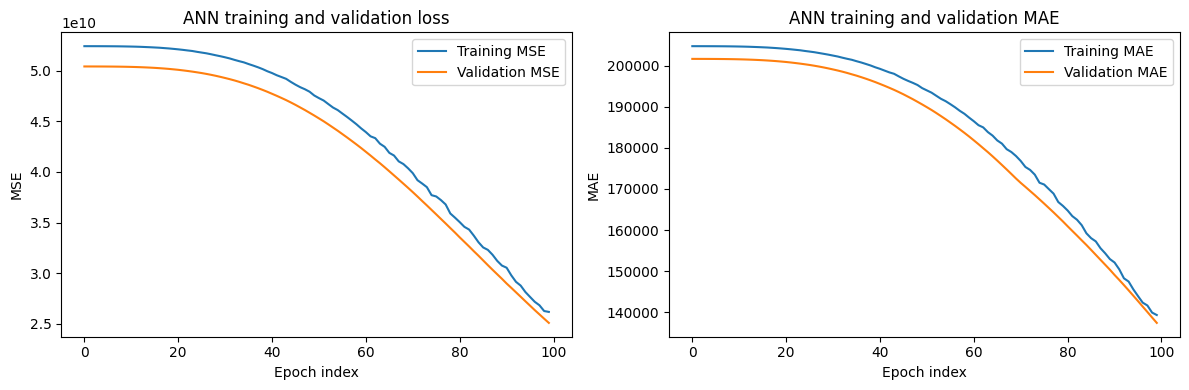

In [12]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_ann.history["loss"], label="Training MSE")
plt.plot(history_ann.history["val_loss"], label="Validation MSE")
plt.title("ANN training and validation loss")
plt.xlabel("Epoch index")
plt.ylabel("MSE")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_ann.history["mae"], label="Training MAE")
plt.plot(history_ann.history["val_mae"], label="Validation MAE")
plt.title("ANN training and validation MAE")
plt.xlabel("Epoch index")
plt.ylabel("MAE")
plt.legend()

plt.tight_layout()
plt.show()

In [13]:
median_target = np.median(y_train)

y_val_pred_baseline = np.full(
    shape=y_val.shape,
    fill_value=median_target
)

baseline_val_mae = mean_absolute_error(y_val, y_val_pred_baseline)
baseline_val_rmse = np.sqrt(
    mean_squared_error(y_val, y_val_pred_baseline)
)

print(f"Baseline validation MAE: {baseline_val_mae:.4f}")
print(f"Baseline validation RMSE: {baseline_val_rmse:.4f}")

Baseline validation MAE: 78153.1484
Baseline validation RMSE: 100471.1028


In [14]:
y_val_pred_ann = ann_model.predict(
    X_val_scaled,
    verbose=0
).ravel()

ann_val_mae = mean_absolute_error(y_val, y_val_pred_ann)
ann_val_rmse = np.sqrt(
    mean_squared_error(y_val, y_val_pred_ann)
)
ann_val_r2 = r2_score(y_val, y_val_pred_ann)

print(f"ANN validation MAE: {ann_val_mae:.4f}")
print(f"ANN validation RMSE: {ann_val_rmse:.4f}")
print(f"ANN validation R²: {ann_val_r2:.4f}")

ANN validation MAE: 137369.1719
ANN validation RMSE: 158440.9741
ANN validation R²: -1.5816


In [15]:
results = {
    "Median baseline": {
        "MAE": baseline_val_mae,
        "RMSE": baseline_val_rmse
    },
    "ANN": {
        "MAE": ann_val_mae,
        "RMSE": ann_val_rmse
    }
}

results_df = pd.DataFrame(results).T

results_df

,MAE,RMSE
Median baseline,78153.148438,100471.102791
ANN,137369.171875,158440.974094


<Figure size 800x400 with 0 Axes>

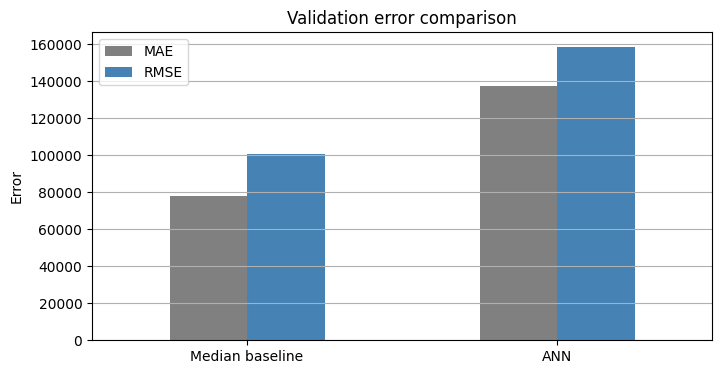

In [16]:
plt.figure(figsize=(8, 4))
results_df.plot(
    kind="bar",
    figsize=(8, 4),
    color=["gray", "steelblue"]
)

plt.title("Validation error comparison")
plt.ylabel("Error")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

In [17]:
y_test_pred_ann = ann_model.predict(
    X_test_scaled,
    verbose=0
).ravel()

ann_test_mae = mean_absolute_error(y_test, y_test_pred_ann)
ann_test_rmse = np.sqrt(
    mean_squared_error(y_test, y_test_pred_ann)
)
ann_test_r2 = r2_score(y_test, y_test_pred_ann)

y_test_pred_baseline = np.full(
    shape=y_test.shape,
    fill_value=median_target
)

baseline_test_mae = mean_absolute_error(
    y_test,
    y_test_pred_baseline
)

baseline_test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_test_pred_baseline
    )
)

print(f"Baseline test MAE: {baseline_test_mae:.4f}")
print(f"Baseline test RMSE: {baseline_test_rmse:.4f}")

print(f"ANN test MAE: {ann_test_mae:.4f}")
print(f"ANN test RMSE: {ann_test_rmse:.4f}")
print(f"ANN test R²: {ann_test_r2:.4f}")

Baseline test MAE: 81932.5156
Baseline test RMSE: 102443.7307
ANN test MAE: 133489.1094
ANN test RMSE: 157958.7746
ANN test R²: -1.4208


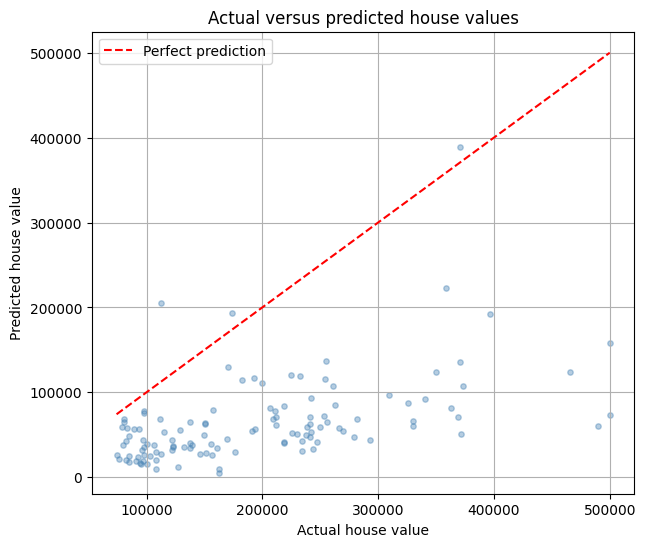

In [18]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    y_test_pred_ann,
    alpha=0.4,
    s=15,
    color="steelblue"
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel("Actual house value")
plt.ylabel("Predicted house value")
plt.title("Actual versus predicted house values")
plt.legend()
plt.grid(True)
plt.show()

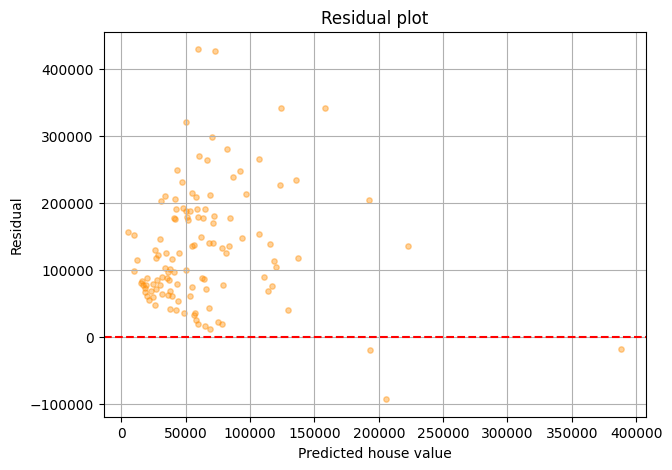

In [19]:
residuals = y_test - y_test_pred_ann

plt.figure(figsize=(7, 5))
plt.scatter(
    y_test_pred_ann,
    residuals,
    alpha=0.4,
    s=15,
    color="darkorange"
)

plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted house value")
plt.ylabel("Residual")
plt.title("Residual plot")
plt.grid(True)
plt.show()

In [20]:
error_df = pd.DataFrame({
    "actual_value": y_test,
    "predicted_value": y_test_pred_ann,
    "residual": residuals,
    "absolute_error": np.abs(residuals)
})

largest_errors = error_df.sort_values(
    "absolute_error",
    ascending=False
).head(20)

largest_errors

,actual_value,predicted_value,residual,absolute_error
9,489600.0,59834.464844,429765.531250,429765.531250
46,500001.0,73044.312500,426956.687500,426956.687500
94,466100.0,123872.812500,342227.187500,342227.187500
14,500001.0,157909.031250,342091.968750,342091.968750
34,371400.0,50362.167969,321037.843750,321037.843750
41,368900.0,70338.539062,298561.468750,298561.468750
68,362800.0,82014.539062,280785.468750,280785.468750
117,330200.0,60062.671875,270137.312500,270137.312500
63,373600.0,107069.539062,266530.468750,266530.468750
10,330000.0,66219.335938,263780.656250,263780.656250


In [21]:
price_bins = [0, 1, 2, 3, 4, 5, np.inf]

price_labels = [
    "0–1",
    "1–2",
    "2–3",
    "3–4",
    "4–5",
    "5+"
]

error_df["price_range"] = pd.cut(
    error_df["actual_value"],
    bins=price_bins,
    labels=price_labels
)

error_by_range = error_df.groupby(
    "price_range",
    observed=True
).agg(
    average_absolute_error=("absolute_error", "mean"),
    count=("absolute_error", "size")
)

error_by_range

,average_absolute_error,count
price_range,,
5+,133489.109375,120


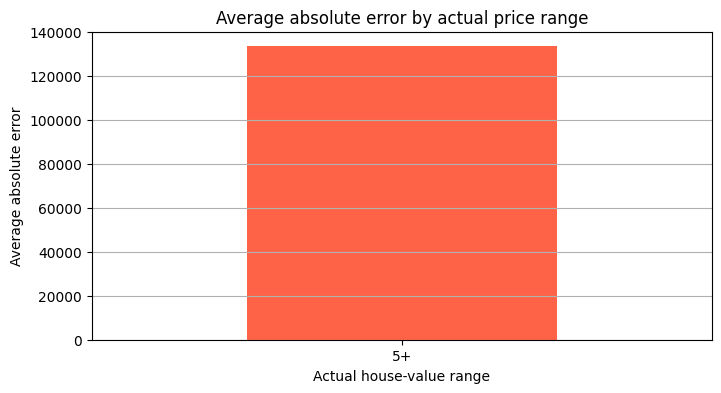

In [22]:
plt.figure(figsize=(8, 4))
error_by_range["average_absolute_error"].plot(
    kind="bar",
    color="tomato"
)

plt.title("Average absolute error by actual price range")
plt.xlabel("Actual house-value range")
plt.ylabel("Average absolute error")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

In [23]:
ann_model.save("house_price_ann_model.keras")

import joblib

joblib.dump(scaler, "house_price_scaler.joblib")

print("Model and scaler saved.")

Model and scaler saved.


In [24]:
new_house = X_test[0:1]

new_house_scaled = scaler.transform(new_house)

predicted_value = ann_model.predict(
    new_house_scaled,
    verbose=0
).ravel()[0]

actual_value = y_test[0]

print(f"Predicted value: {predicted_value:.4f}")
print(f"Actual value: {actual_value:.4f}")
print(f"Prediction error: {abs(predicted_value - actual_value):.4f}")

Predicted value: 83387.9688
Actual value: 218800.0000
Prediction error: 135412.0312
